<a href="https://colab.research.google.com/github/shettypreetham852-preethu/Student-Performance-Prediction/blob/main/Student_Performance_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os

# Create the main project folder
project_path = "/content/Student_Performance_Prediction"

# Create project directories
folders = [
    "dataset",
    "notebook",
    "models",
    "results"
]

for folder in folders:
    os.makedirs(
        os.path.join(project_path, folder),
        exist_ok=True
    )

print("Project structure created successfully!")


Project structure created successfully!


In [ ]:
for root, dirs, files in os.walk(project_path):
    level = root.replace(project_path, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

Student_Performance_Prediction/
    models/
    dataset/
    results/
    notebook/


In [ ]:
import pandas as pd
import zipfile
import io
import urllib.request
import os

# Project dataset folder
dataset_path = "/content/Student_Performance_Prediction/dataset"

# UCI dataset download URL
url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

print("Downloading dataset...")

request = urllib.request.Request(
    url,
    headers={"User-Agent": "Mozilla/5.0"}
)

with urllib.request.urlopen(request) as response:
    zip_data = response.read()

# Open downloaded ZIP file
with zipfile.ZipFile(io.BytesIO(zip_data)) as outer_zip:

    if "student-mat.csv" in outer_zip.namelist():
        csv_data = outer_zip.read("student-mat.csv")

    elif "student.zip" in outer_zip.namelist():
        with zipfile.ZipFile(
            io.BytesIO(outer_zip.read("student.zip"))
        ) as inner_zip:
            csv_data = inner_zip.read("student-mat.csv")

    else:
        raise FileNotFoundError(
            "student-mat.csv was not found in the ZIP file."
        )

# Save dataset into our project folder
csv_path = os.path.join(dataset_path, "student-mat.csv")

with open(csv_path, "wb") as file:
    file.write(csv_data)

print("Dataset downloaded successfully!")
print("Saved at:", csv_path)

Dataset downloaded successfully!
Saved at: /content/Student_Performance_Prediction/dataset/student-mat.csv


In [ ]:
import pandas as pd

csv_path = "/content/Student_Performance_Prediction/dataset/student-mat.csv"

df = pd.read_csv(csv_path, sep=";")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 395
Number of columns: 33


In [ ]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [ ]:
import os

csv_path = "/content/Student_Performance_Prediction/dataset/student-mat.csv"

if os.path.exists(csv_path):
    print("Dataset file exists!")
    print("File size:", round(os.path.getsize(csv_path) / 1024, 2), "KB")
else:
    print("Dataset file not found.")

Dataset file exists!
File size: 55.66 KB


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [ ]:
duplicates = df.duplicated().sum()

print("Duplicate records:", duplicates)

Duplicate records: 0


In [ ]:
for pp in df.columns:
 print(pp)

school
sex
age
address
famsize
Pstatus
Medu
Fedu
Mjob
Fjob
reason
guardian
traveltime
studytime
failures
schoolsup
famsup
paid
activities
nursery
higher
internet
romantic
famrel
freetime
goout
Dalc
Walc
health
absences
G1
G2
G3


In [ ]:
print(df.isnull().sum())

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [ ]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [ ]:
df[["G1", "G2", "G3"]].describe()

,G1,G2,G3
count,395.000000,395.000000,395.000000
mean,10.908861,10.713924,10.415190
std,3.319195,3.761505,4.581443
min,3.000000,0.000000,0.000000
25%,8.000000,9.000000,8.000000
50%,11.000000,11.000000,11.000000
75%,13.000000,13.000000,14.000000
max,19.000000,19.000000,20.000000


In [ ]:
print("Final grade statistics")
print("----------------------")
print("Average grade:", round(df["G3"].mean(), 2))
print("Highest grade:", df["G3"].max())
print("Lowest grade:", df["G3"].min())
print("Median grade:", df["G3"].median())

Final grade statistics
----------------------
Average grade: 10.42
Highest grade: 20
Lowest grade: 0
Median grade: 11.0


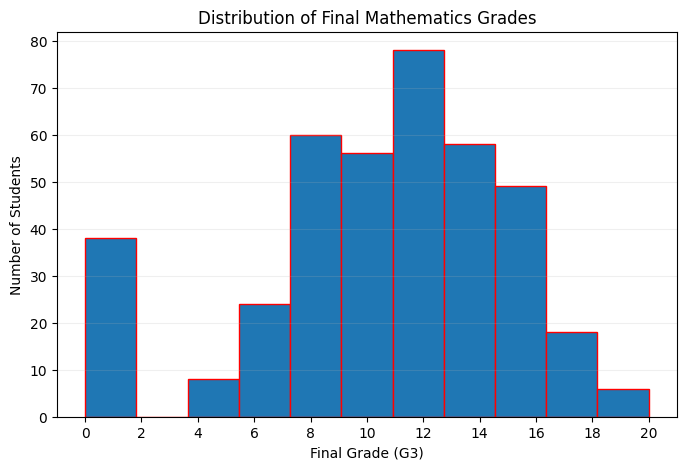

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.hist(df["G3"],bins=11,edgecolor='red')
plt.title("Distribution of Final Mathematics Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")

plt.xticks(range(0, 21, 2))
plt.grid(axis="y", alpha=0.2)

plt.show()

In [ ]:
df['G3'].head()

,G3
0,6
1,6
2,10
3,15
4,10


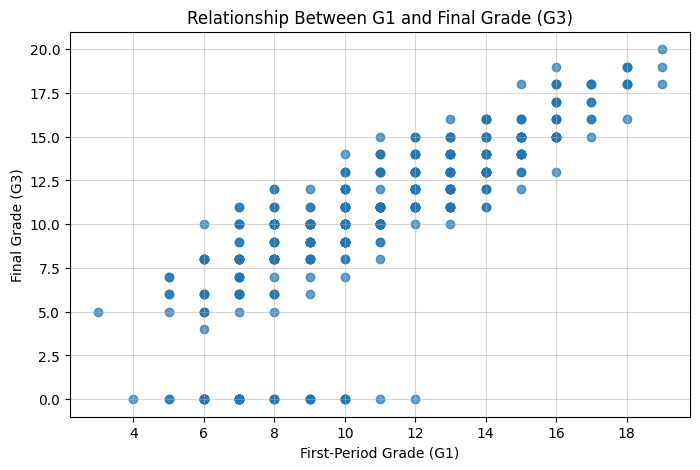

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(df["G1"], df["G3"], alpha=0.7)

plt.title("Relationship Between G1 and Final Grade (G3)")
plt.xlabel("First-Period Grade (G1)")
plt.ylabel("Final Grade (G3)")

plt.grid(True, alpha=0.5)
plt.show()


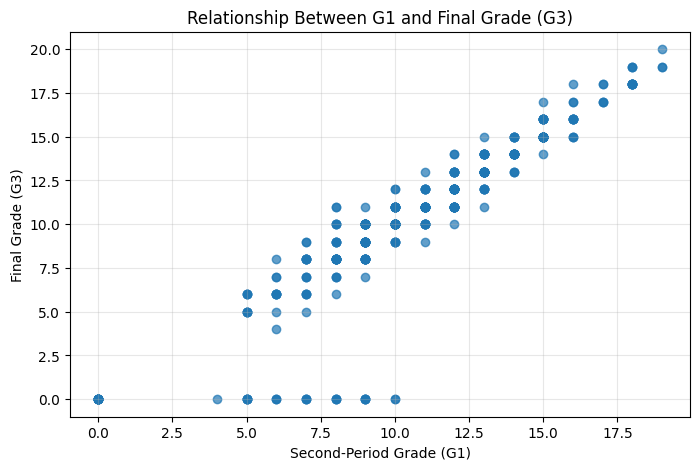

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(df["G2"], df["G3"], alpha=0.7)

plt.title("Relationship Between G1 and Final Grade (G3)")
plt.xlabel("Second-Period Grade (G1)")
plt.ylabel("Final Grade (G3)")

plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
print("Correlation between G1 and G3:", df["G1"].corr(df["G3"]))

Correlation between G1 and G3: 0.8014679320174145


In [ ]:
print("Correlation between G2 and G3:", df["G2"].corr(df["G3"]))

Correlation between G2 and G3: 0.904867989269301


In [ ]:
X = df[["studytime", "failures", "absences", "G1", "G2"]]
Y=df['G3']
print("Input Features (X):")
display(X.head())
print("Input Features (Y):")
display(Y.head())
print("Shape of X:", X.shape)
print("Shape of y:", Y.shape)

Input Features (X):


,studytime,failures,absences,G1,G2
0,2,0,6,5,6
1,2,0,4,5,5
2,2,3,10,7,8
3,3,0,2,15,14
4,2,0,4,6,10


Input Features (Y):


,G3
0,6
1,6
2,10
3,15
4,10


Shape of X: (395, 5)
Shape of y: (395,)


In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42)
print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)

Shape of X_train: (316, 5)
Shape of X_test: (79, 5)


In [ ]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(X_train,Y_train)

LinearRegression()

In [ ]:
print("Model coefficients:", model.coef_)
print("Model intercept:", model.intercept_)

Model coefficients: [-0.07123057 -0.45581289  0.0392449   0.14446336  0.97961532]
Model intercept: -1.6213124035190898


In [ ]:
y_pred = model.predict(X_test)

In [ ]:
print("Predicted final grades:")
print(y_pred[:10].round(2))

Predicted final grades:
[ 6.01 12.2   3.43  8.52  7.87 12.7  18.69  7.1   7.23 12.64]


In [ ]:
import pandas as pd


comparison = pd.DataFrame({
    "Actual Grade": Y_test.to_numpy(),
    "Predicted Grade": y_pred
})


print(comparison.head(10).round(2))

   Actual Grade  Predicted Grade
0            10             6.01
1            12            12.20
2             5             3.43
3            10             8.52
4             9             7.87
5            13            12.70
6            18            18.69
7             6             7.10
8             0             7.23
9            14            12.64


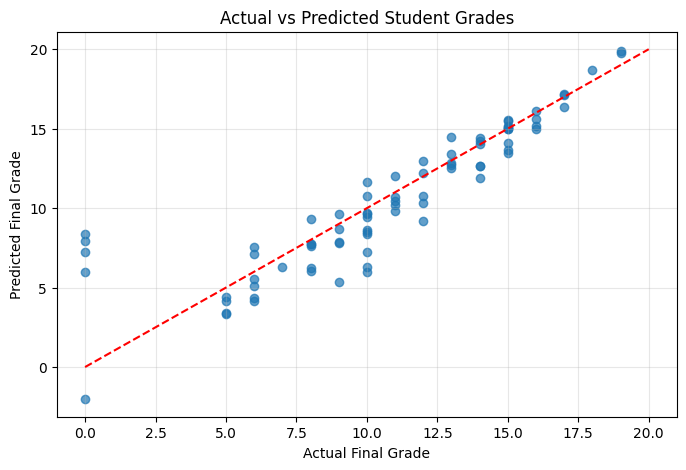

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(Y_test, y_pred, alpha=0.7)

# Reference line: perfect predictions
plt.plot([0, 20], [0, 20], "r--")

plt.xlabel("Actual Final Grade")
plt.ylabel("Predicted Final Grade")
plt.title("Actual vs Predicted Student Grades")

plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate evaluation metrics
mae = mean_absolute_error(Y_test, y_pred)
mse = mean_squared_error(Y_test, y_pred)
r2 = r2_score(Y_test, y_pred)

# Display the results
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("R2 Score:", round(r2, 4))

Mean Absolute Error (MAE): 1.34
Mean Squared Error (MSE): 4.47
R2 Score: 0.7822


In [ ]:
import pandas as pd

results = pd.DataFrame({
    "Metric": ["MAE", "MSE", "R2 Score"],
    "Value": [mae, mse, r2]
})

display(results.round(4))

,Metric,Value
0,MAE,1.3394
1,MSE,4.4665
2,R2 Score,0.7822


In [ ]:
def predict_student_grade(studytime, failures, absences, G1, G2):


    student_data = [[studytime, failures, absences, G1, G2]]


    predicted_grade = model.predict(student_data)[0]


    predicted_grade = max(0, min(20, predicted_grade))

    print("Predicted Final Grade:", round(predicted_grade, 2), "/ 20")


print("Student Grade Prediction System is Ready!")

Student Grade Prediction System is Ready!


In [ ]:
predict_student_grade(
    studytime=2,
    failures=0,
    absences=4,
    G1=12,
    G2=14
)

Predicted Final Grade: 13.84 / 20


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [ ]:
import pandas as pd

def predict_student_grade(studytime, failures, absences, G1, G2):

    student_data = pd.DataFrame([{
        "studytime": studytime,
        "failures": failures,
        "absences": absences,
        "G1": G1,
        "G2": G2
    }])

    predicted_grade = model.predict(student_data)[0]

    predicted_grade = max(0, min(20, predicted_grade))

    print("Predicted Final Grade:", round(predicted_grade, 2), "/ 20")

In [ ]:
import os
import joblib

model_path = "/content/Student_Performance_Prediction/models/student_performance_model.pkl"


joblib.dump(model, model_path)

print("Model saved successfully!")
print("Saved location:", model_path)

Model saved successfully!
Saved location: /content/Student_Performance_Prediction/models/student_performance_model.pkl


In [ ]:
import os

if os.path.exists(model_path):
    print("Model file exists!")
    print("File size:", os.path.getsize(model_path), "bytes")
else:
    print("Model file not found.")

Model file exists!
File size: 913 bytes


In [ ]:
from google.colab import files

files.download(model_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install gradio

In [ ]:
import gradio as gr
import pandas as pd

def predict_grade(studytime, failures, absences, G1, G2):

    student_data = pd.DataFrame([{
        "studytime": studytime,
        "failures": failures,
        "absences": absences,
        "G1": G1,
        "G2": G2
    }])

    prediction = model.predict(student_data)[0]


    prediction = max(0, min(20, prediction))

    return f"Predicted Final Grade: {prediction:.2f} / 20"


app = gr.Interface(
    fn=predict_grade,
    inputs=[
        gr.Slider(1, 4, value=2, step=1, label="Study Time (1–4)"),
        gr.Number(value=0, label="Previous Failures"),
        gr.Number(value=4, label="Absences"),
        gr.Slider(0, 20, value=12, step=1, label="First-Period Grade (G1)"),
        gr.Slider(0, 20, value=14, step=1, label="Second-Period Grade (G2)")
    ],
    outputs=gr.Textbox(label="Prediction"),
    title="Student Performance Prediction System",
    description="Enter student information to estimate the final mathematics grade."
)

app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5eb4e0abffa7af28f3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import os

project_path = "/content/Student_Performance_Prediction"

for root, dirs, files in os.walk(project_path):
    print(root)
    for file in files:
        print("  ", file)

/content/Student_Performance_Prediction
/content/Student_Performance_Prediction/models
   student_performance_model.pkl
/content/Student_Performance_Prediction/dataset
   student-mat.csv
/content/Student_Performance_Prediction/results
/content/Student_Performance_Prediction/notebook
